In [1]:
from pathlib import Path

try:
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
except ImportError as exc:
    raise ImportError(
        "Install the notebook dependencies with `%pip install pandas matplotlib` "
        "and rerun this cell."
    ) from exc

log_path = Path("closed-loop-filter-on.log")
if not log_path.is_file():
    raise FileNotFoundError(f"Expected the log next to this notebook: {log_path.resolve()}")

columns = [
    "time_s", "state", "desired_speed_mps", "voltage_left_v", "voltage_right_v",
    "encoder_left", "encoder_right", "wheel_speed_left_radps", "wheel_speed_right_radps",
    "battery_v", "gyro_x_dps", "gyro_y_dps", "gyro_z_dps", "current_left_a",
    "current_right_a", "pose_x_m", "pose_y_m", "heading_rad", "distance_m",
    "forward_speed_mps", "turn_rate_radps", "wheel_speed_left_filtered_radps",
    "wheel_speed_right_filtered_radps",
]

data = pd.read_csv(log_path, comment="%", sep=r"\s+", header=None)
if data.empty:
    raise ValueError(f"No numeric log rows found in {log_path}")
if data.shape[1] == 21:
    data.columns = columns[:21]
    filter_alpha = 0.1
    sample_time_s = None
    with log_path.open("r", encoding="utf-8") as log_file:
        for line in log_file:
            if line.startswith("% Sample time "):
                sample_time_s = float(line.split()[3]) * 1e-6
                break
    if sample_time_s is None or sample_time_s <= 0.0:
        raise ValueError("Legacy log is missing a valid sample-time header")
    timestamps = data["time_s"].to_numpy()

    def estimate_ema(values):
        filtered = np.empty_like(values, dtype=float)
        filtered[0] = values[0]
        for index in range(1, len(values)):
            elapsed = max(0.0, timestamps[index] - timestamps[index - 1])
            alpha = 1.0 - (1.0 - filter_alpha) ** (elapsed / sample_time_s)
            filtered[index] = filtered[index - 1] + alpha * (values[index] - filtered[index - 1])
        return filtered

    data["wheel_speed_left_filtered_radps"] = estimate_ema(
        data["wheel_speed_left_radps"].to_numpy()
    )
    data["wheel_speed_right_filtered_radps"] = estimate_ema(
        data["wheel_speed_right_radps"].to_numpy()
    )
    filter_source = "EMA estimate (legacy log)"
elif data.shape[1] == 23:
    data.columns = columns
    filter_source = "EMA-filtered"
else:
    raise ValueError(f"Expected 21 or 23 numeric columns, found {data.shape[1]}")

if data.isna().any().any():
    raise ValueError("Some log rows contain missing values")

data.head()

,time_s,state,desired_speed_mps,voltage_left_v,voltage_right_v,encoder_left,encoder_right,wheel_speed_left_radps,wheel_speed_right_radps,battery_v,...,current_left_a,current_right_a,pose_x_m,pose_y_m,heading_rad,distance_m,forward_speed_mps,turn_rate_radps,wheel_speed_left_filtered_radps,wheel_speed_right_filtered_radps
0,0.000,1,0.0,0.0,0.0,0,0,0.0,0.0,12.06,...,-0.11,0.11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.001,1,0.0,0.0,0.0,0,0,0.0,0.0,12.07,...,-0.11,0.11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.002,1,0.0,0.0,0.0,0,0,0.0,0.0,12.07,...,-0.11,0.10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.003,1,0.0,0.0,0.0,0,0,0.0,0.0,12.07,...,-0.11,0.11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.004,1,0.0,0.0,0.0,0,0,0.0,0.0,12.07,...,-0.12,0.12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [2]:
time = data["time_s"].to_numpy()
dt = np.diff(time)
duration_s = float(time[-1] - time[0]) if len(time) > 1 else 0.0
median_interval_s = float(np.median(dt)) if len(dt) else float("nan")

print(f"Rows: {len(data)}")
print(f"Time range: {time[0]:.4f} to {time[-1]:.4f} s ({duration_s:.3f} s recorded)")
print(f"Median log interval: {median_interval_s:.4f} s")
print(f"Observed states: {sorted(data['state'].unique().tolist())}")
display(data[[
    "desired_speed_mps", "forward_speed_mps", "distance_m", "voltage_left_v",
    "voltage_right_v", "battery_v", "current_left_a", "current_right_a",
]].describe().T.round(3))

Rows: 3084
Time range: 0.0000 to 3.0830 s (3.083 s recorded)
Median log interval: 0.0010 s
Observed states: [1, 2, 3]


,count,mean,std,min,25%,50%,75%,max
desired_speed_mps,3084.0,0.358,0.122,0.00,0.40,0.40,0.400,0.40
forward_speed_mps,3084.0,0.325,0.118,-0.19,0.35,0.36,0.380,0.55
distance_m,3084.0,0.544,0.316,0.00,0.27,0.55,0.830,1.01
voltage_left_v,3084.0,1.201,1.515,-9.00,0.82,1.23,1.792,9.00
voltage_right_v,3084.0,1.190,1.512,-9.00,0.78,1.25,1.830,9.00
battery_v,3084.0,12.035,0.067,11.49,12.03,12.05,12.060,12.08
current_left_a,3084.0,-0.062,0.388,-2.13,-0.26,-0.14,0.170,1.82
current_right_a,3084.0,0.152,0.363,-1.66,-0.02,0.08,0.400,1.93


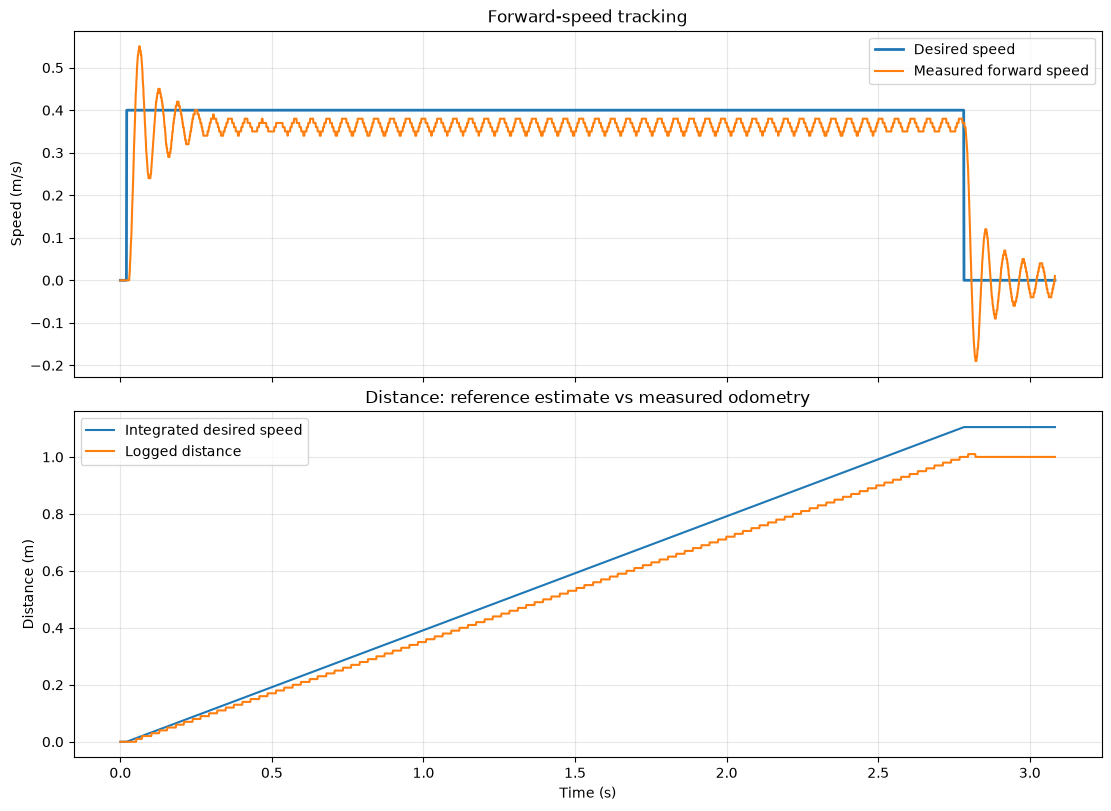

Final logged distance: 1.000 m
Final integrated reference distance: 1.105 m


In [3]:
# Integrate the speed reference using the measured, possibly nonuniform log intervals.
reference_speed = data["desired_speed_mps"].to_numpy()
reference_distance = np.zeros(len(data))
if len(data) > 1:
    reference_distance[1:] = np.cumsum(
        0.5 * (reference_speed[:-1] + reference_speed[1:]) * dt
    )

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True, constrained_layout=True)
axes[0].plot(time, reference_speed, label="Desired speed", linewidth=2)
axes[0].plot(time, data["forward_speed_mps"], label="Measured forward speed")
axes[0].set_ylabel("Speed (m/s)")
axes[0].set_title("Forward-speed tracking")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(time, reference_distance, label="Integrated desired speed")
axes[1].plot(time, data["distance_m"], label="Logged distance")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Distance (m)")
axes[1].set_title("Distance: reference estimate vs measured odometry")
axes[1].grid(True, alpha=0.3)
axes[1].legend()
plt.show()

print(f"Final logged distance: {data['distance_m'].iloc[-1]:.3f} m")
print(f"Final integrated reference distance: {reference_distance[-1]:.3f} m")

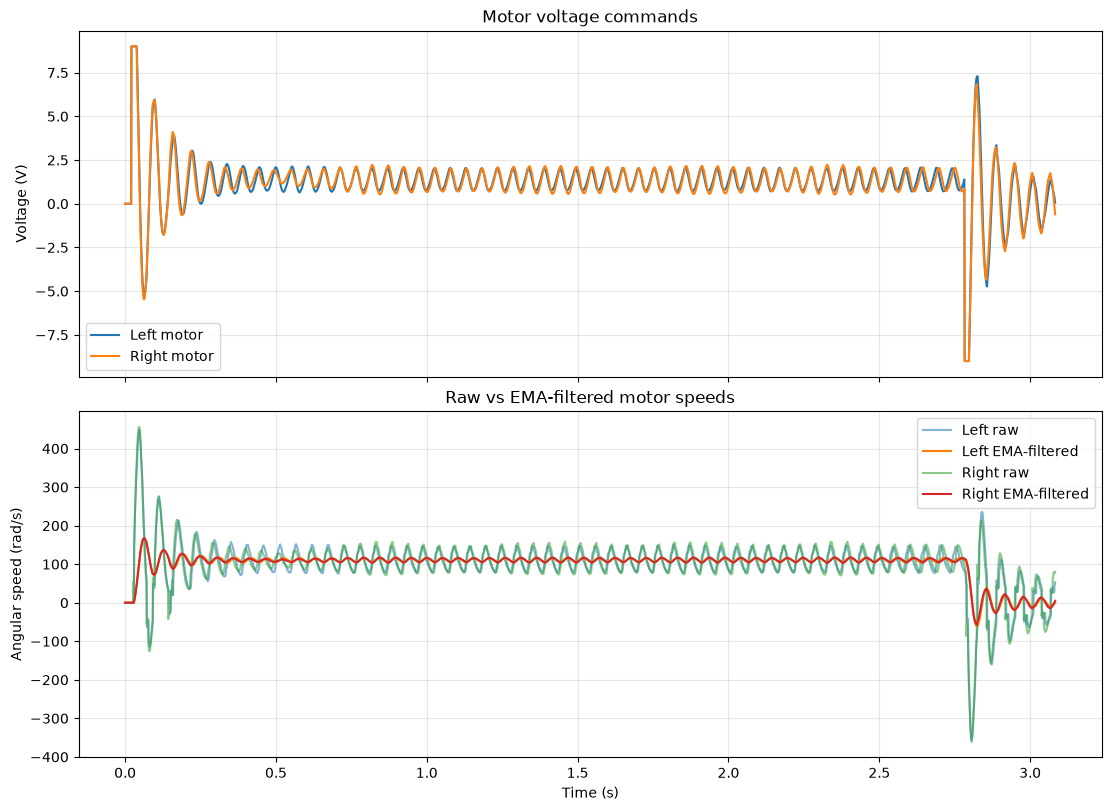

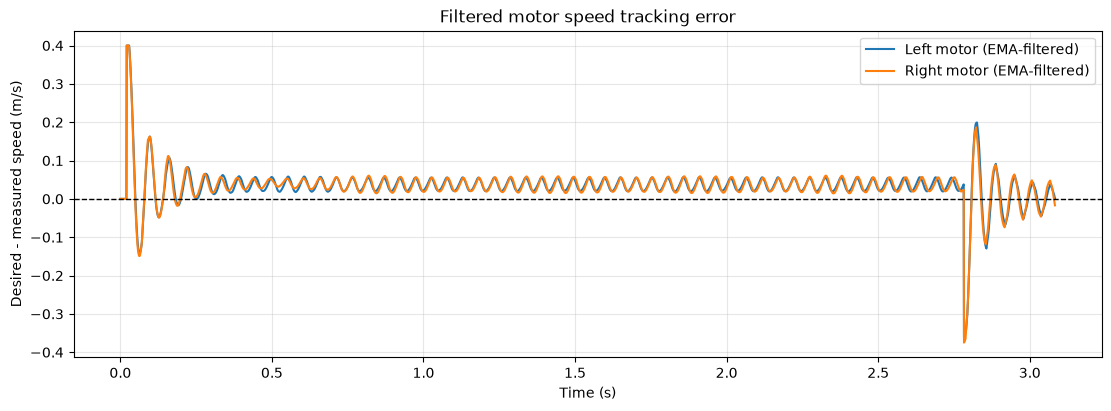

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True, constrained_layout=True)
axes[0].plot(time, data["voltage_left_v"], label="Left motor")
axes[0].plot(time, data["voltage_right_v"], label="Right motor")
axes[0].set_ylabel("Voltage (V)")
axes[0].set_title("Motor voltage commands")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(time, data["wheel_speed_left_radps"], label="Left raw", alpha=0.55)
axes[1].plot(time, data["wheel_speed_left_filtered_radps"], label=f"Left {filter_source}")
axes[1].plot(time, data["wheel_speed_right_radps"], label="Right raw", alpha=0.55)
axes[1].plot(time, data["wheel_speed_right_filtered_radps"], label=f"Right {filter_source}")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Angular speed (rad/s)")
axes[1].set_title("Raw vs EMA-filtered motor speeds")
axes[1].grid(True, alpha=0.3)
axes[1].legend()
plt.show()

gear_ratio = 9.6
wheel_radius_m = 0.0315
reference_speed_mps = data["desired_speed_mps"].to_numpy()
left_measured_speed_mps = data["wheel_speed_left_filtered_radps"].to_numpy() * wheel_radius_m / gear_ratio
right_measured_speed_mps = data["wheel_speed_right_filtered_radps"].to_numpy() * wheel_radius_m / gear_ratio
left_speed_error_mps = reference_speed_mps - left_measured_speed_mps
right_speed_error_mps = reference_speed_mps - right_measured_speed_mps

fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
ax.plot(time, left_speed_error_mps, label=f"Left motor ({filter_source})")
ax.plot(time, right_speed_error_mps, label=f"Right motor ({filter_source})")
ax.axhline(0.0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Desired - measured speed (m/s)")
ax.set_title("Filtered motor speed tracking error")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

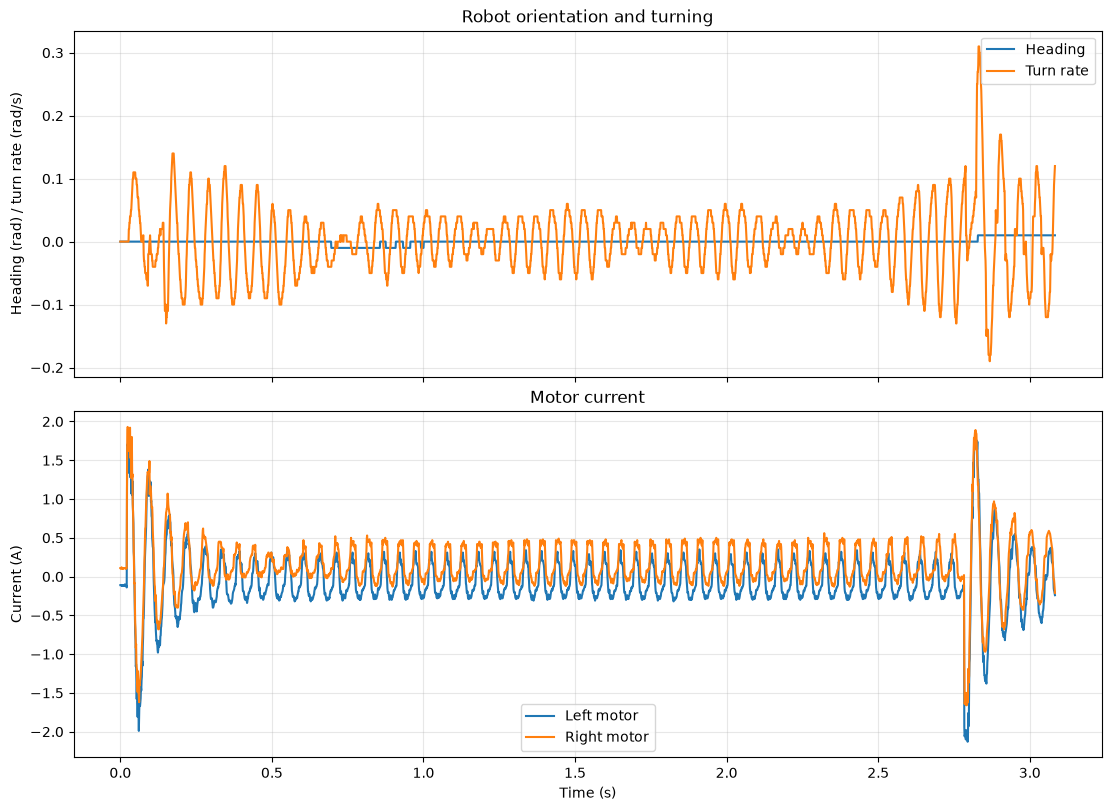

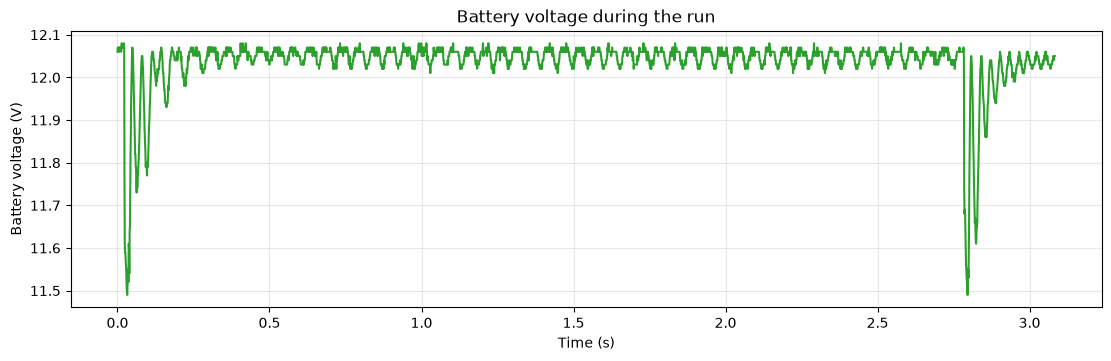

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True, constrained_layout=True)
axes[0].plot(time, data["heading_rad"], label="Heading")
axes[0].plot(time, data["turn_rate_radps"], label="Turn rate")
axes[0].set_ylabel("Heading (rad) / turn rate (rad/s)")
axes[0].set_title("Robot orientation and turning")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(time, data["current_left_a"], label="Left motor")
axes[1].plot(time, data["current_right_a"], label="Right motor")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Current (A)")
axes[1].set_title("Motor current")
axes[1].grid(True, alpha=0.3)
axes[1].legend()
plt.show()

fig, ax = plt.subplots(figsize=(11, 3.5), constrained_layout=True)
ax.plot(time, data["battery_v"], color="tab:green")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Battery voltage (V)")
ax.set_title("Battery voltage during the run")
ax.grid(True, alpha=0.3)
plt.show()

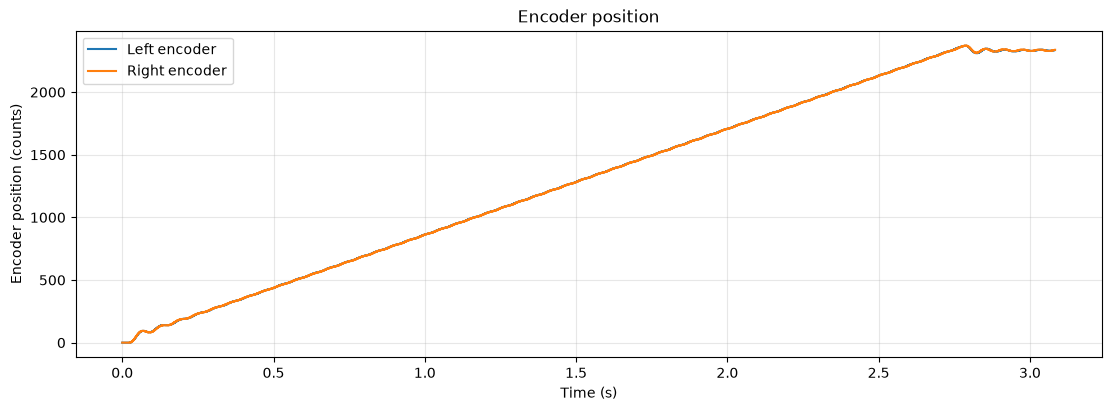

In [6]:
fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
ax.step(time, data["encoder_left"], where="post", label="Left encoder")
ax.step(time, data["encoder_right"], where="post", label="Right encoder")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Encoder position (counts)")
ax.set_title("Encoder position")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

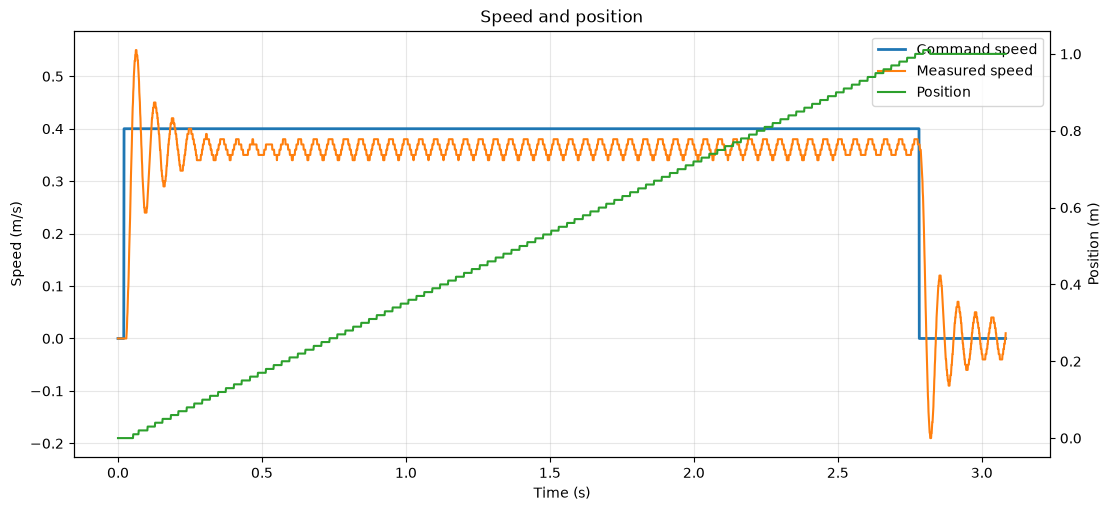

In [7]:
fig, speed_ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
position_ax = speed_ax.twinx()

speed_ax.plot(time, data["desired_speed_mps"], label="Command speed", linewidth=2)
speed_ax.plot(time, data["forward_speed_mps"], label="Measured speed")
position_ax.plot(time, data["distance_m"], label="Position", color="tab:green")

speed_ax.set_xlabel("Time (s)")
speed_ax.set_ylabel("Speed (m/s)")
position_ax.set_ylabel("Position (m)")
speed_ax.set_title("Speed and position")
speed_ax.grid(True, alpha=0.3)
lines = speed_ax.get_lines() + position_ax.get_lines()
speed_ax.legend(lines, [line.get_label() for line in lines], loc="best")
plt.show()

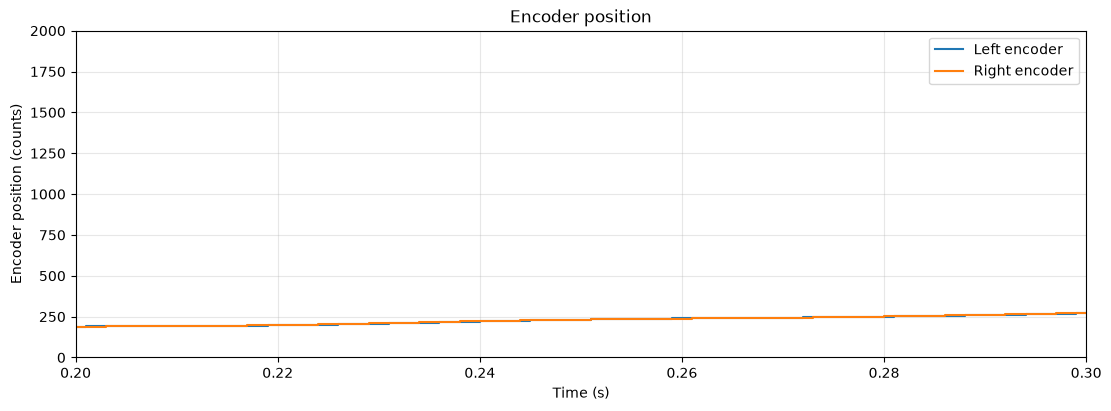

In [8]:
fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
ax.step(time, data["encoder_left"], where="post", label="Left encoder")
ax.step(time, data["encoder_right"], where="post", label="Right encoder")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Encoder position (counts)")
ax.set_title("Encoder position")
ax.grid(True, alpha=0.3)
plt.xlim(0.2,0.3)
plt.ylim(0,2000)
ax.legend()
plt.show()